# Machine Learning — Sesioni 1

## Hyrje në ML + Linear Regression (një veçori)

**Çka do të bëjmë sot:**
1. Kuptojmë çka është Machine Learning
2. Ndajmë të dhënat në train/test (80/20)
3. Trajnojmë modelin e parë Linear Regression
4. Vlerësojmë me MSE dhe R²

**Dataseti:** `employees_enhanced.csv` — 100 punonjës (vendoseni në të njëjtin folder me notebook-un; ka `vite_pune` dhe `churn`)

**Target:** Parashikojmë **Paga** (€) nga **Mosha** (vite)

**Çka është ML (shkurt):** Jepni shembuj (moshë → pagë) dhe kompjuteri gjen rregullin. Pastaj e përdor për punonjës të rinj.

## Hapi 0 — Importet

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# pip install scikit-learn

## Hapi 1 — Lexojmë datasetin

In [2]:
# Lexojmë CSV-në — duhet të jetë në të njëjtin folder me këtë notebook
df = pd.read_csv('../data/employees_enhanced.csv')

print(f'Rreshta: {df.shape[0]}, Kolona: {df.shape[1]}')
print('Kolonat:', list(df.columns))
df.head()


Rreshta: 100, Kolona: 11
Kolonat: ['EmployeeID', 'Emri', 'Departamenti', 'Qyteti', 'Mosha', 'Rating', 'Bonus', 'Data_Punesimit', 'vite_pune', 'Paga', 'churn']


,EmployeeID,Emri,Departamenti,Qyteti,Mosha,Rating,Bonus,Data_Punesimit,vite_pune,Paga,churn
0,2001,Genta,Finance,Prishtinë,26,1.0,391,2018-08-07,1.4,2721.80,1
1,2002,Drita,Ops,Durrës,40,5.0,446,2011-05-26,8.6,4473.62,0
2,2003,Hana,Sales,Pejë,25,4.0,236,2017-07-01,2.5,3385.93,0
3,2004,Edon,Marketing,Pejë,56,5.0,68,2007-03-14,12.8,4578.26,0
4,2005,Genta,IT,Prizren,38,1.0,226,2015-04-20,4.7,2845.99,1


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   EmployeeID      100 non-null    int64  
 1   Emri            100 non-null    str    
 2   Departamenti    100 non-null    str    
 3   Qyteti          100 non-null    str    
 4   Mosha           100 non-null    int64  
 5   Rating          100 non-null    float64
 6   Bonus           100 non-null    int64  
 7   Data_Punesimit  100 non-null    str    
 8   vite_pune       100 non-null    float64
 9   Paga            100 non-null    float64
 10  churn           100 non-null    int64  
dtypes: float64(3), int64(4), str(4)
memory usage: 8.7 KB


In [4]:
df.describe()


,EmployeeID,Mosha,Rating,Bonus,vite_pune,Paga,churn
count,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000
mean,2050.500000,41.630000,2.980000,265.89000,7.337000,3668.995000,0.440000
std,29.011492,11.017575,1.483784,129.02579,3.914223,638.935631,0.498888
min,2001.000000,22.000000,1.000000,54.00000,1.000000,2213.390000,0.000000
25%,2025.750000,33.000000,2.000000,174.00000,3.875000,3249.237500,0.000000
50%,2050.500000,44.000000,3.000000,247.00000,7.650000,3670.515000,0.000000
75%,2075.250000,51.000000,4.000000,388.00000,10.525000,4147.832500,1.000000
max,2100.000000,58.000000,5.000000,494.00000,14.100000,4928.330000,1.000000


## Hapi 2 — Vizualizim: Mosha vs Paga

Para se të trajnojmë modelin, të shohim me sy nëse ka lidhje mes Moshës dhe Pagës.

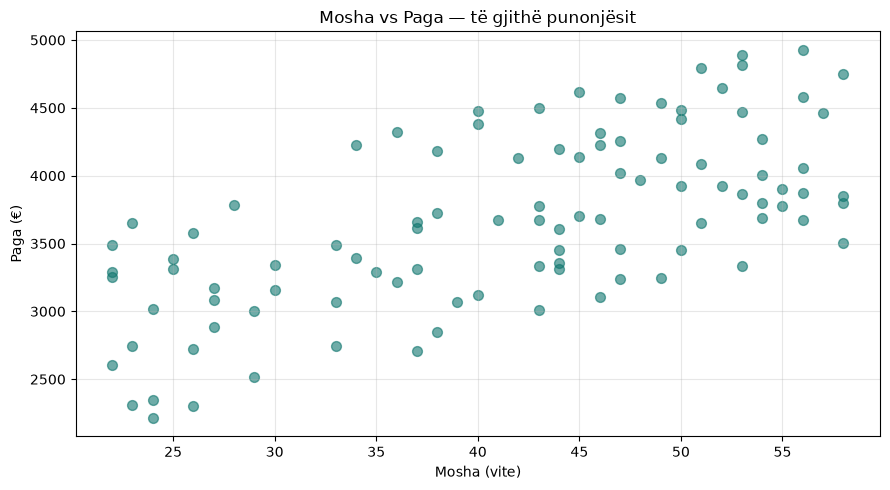

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(df['Mosha'], df['Paga'], alpha=0.6, color='#0F766E', s=50)
plt.xlabel('Mosha (vite)')
plt.ylabel('Paga (€)')
plt.title('Mosha vs Paga — të gjithë punonjësit')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Vërejtje:** Shohim një tendencë — mosha më e lartë → paga më e lartë. Modeli s'do të jetë perfekt.

## Hapi 3 — Train / Test Split (80 / 20)

Ndajmë datasetin që të matim modelin në të dhëna që s'i ka parë.

In [6]:
# X = veçoritë (input)  |  y = target
# sklearn kërkon X me kllapa të dyfishta [['Mosha']] — edhe për 1 kolonë!
X = df[['Mosha']]
y = df['Paga']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f'Train: {X_train.shape[0]} punonjës  (modeli mëson nga këta)')
print(f'Test:  {X_test.shape[0]} punonjës  (vlerësojmë këtu)')


Train: 80 punonjës  (modeli mëson nga këta)
Test:  20 punonjës  (vlerësojmë këtu)


## Hapi 4 — Trajnojmë modelin

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f'Pjerrësia (m): {model.coef_[0]:.2f} € për çdo vit të moshës')
print(f'Intercept (b): {model.intercept_:.2f} €')
print(f'Formula: Paga ≈ {model.coef_[0]:.2f} × Mosha + {model.intercept_:.2f}')


Pjerrësia (m): 39.80 € për çdo vit të moshës
Intercept (b): 2004.51 €
Formula: Paga ≈ 39.80 × Mosha + 2004.51


## Hapi 5 — Parashikojmë dhe vlerësojmë

In [8]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2  = r2_score(y_test, y_pred)

print(f'MSE  = {mse:.0f} €²')
print(f'RMSE = {rmse:.0f} € (gabimi mesatar në €)')
print(f'R²   = {r2:.3f}  (sa % të variacionit shpjegon modeli)')


MSE  = 201884 €²
RMSE = 449 € (gabimi mesatar në €)
R²   = 0.377  (sa % të variacionit shpjegon modeli)


###  Si t'i lexojmë numrat?

- **R² ~ 0.40** → mosha shpjegon ~40% të variacionit të pagës
- **RMSE ~ 550 €** → gabim mesatar ~550 € për punonjës
- Sesionin tjetër shtojmë më shumë veçori → R² rritet

##  Hapi 6 — Vijëzojmë modelin mbi scatter plot

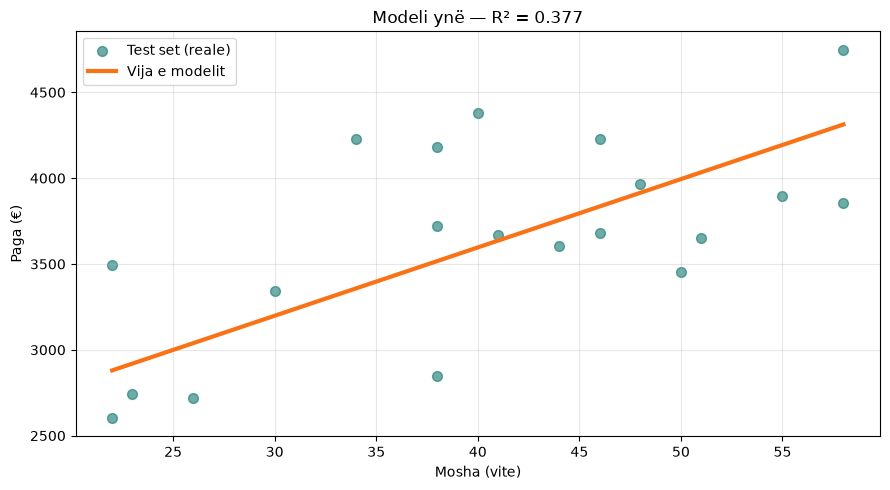

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(X_test, y_test, alpha=0.6, color='#0F766E', s=50, label='Test set (reale)')

X_line = pd.DataFrame({'Mosha': np.linspace(X['Mosha'].min(), X['Mosha'].max(), 100)})
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='#F97316', linewidth=3, label='Vija e modelit')

plt.xlabel('Mosha (vite)')
plt.ylabel('Paga (€)')
plt.title(f'Modeli ynë — R² = {r2:.3f}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


##  Ushtrim praktik

1. Ndryshoni `random_state` dhe shikoni R²
2. Provoni `Bonus` në vend të `Mosha`
3. Pse RMSE është më i lehtë se MSE?